## 1. Análise Exploratória de Dados (EDA)

A primeira etapa do projeto é olhar os dados antes de usá-los: entender o que eles contêm, como estão organizados e se servem para o que queremos fazer.

O CGMacros tem 45 participantes acompanhados por cerca de 10 dias. Nesse período, cada pessoa usou um sensor de glicose (CGM) colado no braço e uma pulseira Fitbit, que registra atividade e frequência cardíaca, e anotou as refeições que fez. Cada participante tem um arquivo CSV próprio, com uma linha por minuto.

As bibliotecas usadas aqui estão instaladas no ambiente virtual do projeto (`.venv`).

In [5]:
import pandas as pd

Como são 45 participantes, cada um com o seu arquivo, cada etapa vira uma função que recebe o número do participante. Assim o mesmo código roda para todos sem ser copiado. A primeira é a `carregar`, que lê o arquivo, limpa os nomes das colunas e converte o horário.

In [ ]:
# função para a leitura das informações
from pathlib import Path
RAW = Path('../data/raw')

def carregar(pid):
    # função para a leitura dos 45 datasets
    df = pd.read_csv(RAW / f'CGMacros-{pid:03d}' / f'CGMacros-{pid:03d}.csv')
    # remove espaços nas pontas dos nomes das colunas (ex.: 'Amount Consumed ' no 001)
    df.columns = df.columns.str.strip()
    # convertendo coluna de timestamp com a função to_datetime do pandas
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    # determinando o pid do paciente numa coluna específica
    df['pid'] = pid
    return df

# testando no primeiro paciente
df = carregar(1)
df.head()

Para ter uma visão geral de um participante, a função `visao_geral(pid)` junta num lugar só o período do registro, a frequência das linhas, as colunas, os dois sensores de glicose, o Fitbit, as refeições e os dados do `bio.csv`. Para olhar outro participante, basta trocar o número (ex.: `visao_geral(7)`).

In [35]:
def visao_geral(pid):
    """Resumo de um participante: período, frequência, sensores, Fitbit, refeições e bio."""
    df = carregar(pid)
    n_datas = df['Timestamp'].dt.date.nunique()

    print(f'===== Participante {pid:03d} =====')

    # 1) período e frequência das linhas
    passo = df['Timestamp'].diff().value_counts().head(3)
    print('\n[Período]')
    print('início:', df['Timestamp'].min(), '| fim:', df['Timestamp'].max())
    print('linhas:', len(df), '| datas no calendário:', n_datas)
    print('intervalo mais comum entre linhas:', passo.index[0], f'({passo.iloc[0]} vezes)')

    # 2) colunas
    print('\n[Colunas]')
    print(df.columns.tolist())

    # 3) sensores de glicose: quantos minutos têm valor e quantas são medições "novas"
    print('\n[Sensores de glicose]')
    for col in ['Libre GL', 'Dexcom GL']:
        s = df[col]
        # numa reta interpolada a variação por minuto se repete; uma medição nova é onde ela muda
        # (é uma estimativa: duas medições seguidas com a mesma inclinação contam como uma)
        variacao = s.diff().round(4)
        reais = (variacao != variacao.shift()).sum()
        print(f'{col}: com valor em {s.notna().mean():.0%} dos minutos | '
              f'média {s.mean():.0f} mg/dL | mín {s.min():.0f} | máx {s.max():.0f} | '
              f'~{reais / n_datas:.0f} medições reais por dia')

    # 4) Fitbit (nem todo arquivo tem todas as colunas)
    print('\n[Fitbit]')
    for col in ['HR', 'Calories (Activity)', 'METs']:
        if col in df.columns:
            print(f'{col}: com valor em {df[col].notna().mean():.0%} dos minutos | média {df[col].mean():.2f}')
        else:
            print(f'{col}: coluna ausente neste arquivo')

    # 5) refeições: só a linha do minuto em que a refeição começou é preenchida
    ref = df[df['Meal Type'].notna()]
    print('\n[Refeições]')
    print('total:', len(ref), '| por dia:', round(len(ref) / n_datas, 1))
    print('tipos:', ref['Meal Type'].value_counts().to_dict())
    cols_ref = [c for c in ['Timestamp', 'Meal Type', 'Calories', 'Carbs', 'Protein', 'Fat', 'Fiber', 'Amount Consumed']
                if c in df.columns]
    print('exemplo:')
    print(ref[cols_ref].head(3).to_string(index=False))

    # 6) bio.csv (uma linha por participante)
    bio_p = pd.read_csv(RAW / 'bio.csv')
    b = bio_p[bio_p['subject'] == pid].iloc[0]
    print('\n[bio.csv]')
    print(f"idade {b['Age']} | sexo {b['Gender']} | IMC {b['BMI']:.1f} | "
          f"HbA1c {b['A1c PDL (Lab)']}% | glicemia de jejum {b['Fasting GLU - PDL (Lab)']} mg/dL")

visao_geral(1)

===== Participante 001 =====

[Período]
início: 2020-05-01 10:30:00 | fim: 2020-05-11 15:59:00
linhas: 14730 | datas no calendário: 11
intervalo mais comum entre linhas: 0 days 00:01:00 (14729 vezes)

[Colunas]
['Unnamed: 0', 'Timestamp', 'Libre GL', 'Dexcom GL', 'HR', 'Calories (Activity)', 'METs', 'Meal Type', 'Calories', 'Carbs', 'Protein', 'Fat', 'Fiber', 'Amount Consumed ', 'Image path', 'pid']

[Sensores de glicose]
Libre GL: com valor em 100% dos minutos | média 89 mg/dL | mín 54 | máx 127 | ~81 medições reais por dia
Dexcom GL: com valor em 97% dos minutos | média 107 mg/dL | mín 40 | máx 176 | ~270 medições reais por dia

[Fitbit]
HR: com valor em 99% dos minutos | média 71.80
Calories (Activity): com valor em 100% dos minutos | média 2.12
METs: com valor em 100% dos minutos | média 20.24

[Refeições]
total: 43 | por dia: 3.9
tipos: {'Dinner': 14, 'Lunch': 10, 'Breakfast': 10, 'Snacks': 9}
exemplo:
          Timestamp Meal Type  Calories  Carbs  Protein  Fat  Fiber
2020-05-01 

No participante 001, o registro vai das 10h30 de 01/05 às 15h59 de 11/05: são 11 datas do calendário e 14.730 linhas, uma por minuto. Além da glicose, do Fitbit e das refeições, aparece uma coluna `Unnamed: 0`, que é só o número da linha salvo junto com o arquivo.

O mais interessante está nos sensores. Os dois têm valor em quase todos os minutos, mas o número de medições reais é bem diferente: cerca de 81 por dia no Libre e 270 no Dexcom. Isso bate com o Libre medindo a cada 15 minutos e o Dexcom a cada 5, com os minutos do meio preenchidos. Os valores também não coincidem: a média do Libre é 89 mg/dL, e a do Dexcom, 107.

O Fitbit está praticamente completo. Foram 43 refeições, umas 4 por dia, cada uma numa única linha, no minuto em que começou. Pelo `bio.csv`, é um homem de 27 anos, com IMC de 22,3, HbA1c de 5,4% e glicemia de jejum de 91 mg/dL, ou seja, do grupo saudável.

A contagem de medições reais é uma estimativa (a função conta as mudanças de inclinação da curva) e fica um pouco abaixo do esperado, 96 e 288, porque os dias parciais entram na conta.

Cada linha é um minuto, então um dia inteiro tem 1440 linhas. Abaixo, `min()` e `max()` mostram quando o registro começa e termina, e `groupby(...).size()` conta quantos minutos há em cada data.

Isso importa porque a rede vai trabalhar com a glicose média de cada dia. Se um dia tiver só uma parte registrada (sem a madrugada, por exemplo), a média dele não pode ser comparada com a de um dia inteiro.

Essa contagem, porém, só diz que a linha existe. Se o sensor mediu de fato a glicose naqueles minutos é outra pergunta, que vem logo depois.

In [20]:
print(df['Timestamp'].min(), df['Timestamp'].max())
print(df.groupby(df['Timestamp'].dt.date).size())

2020-05-01 10:30:00 2020-05-11 15:59:00
Timestamp
2020-05-01     810
2020-05-02    1440
2020-05-03    1440
2020-05-04    1440
2020-05-05    1440
2020-05-06    1440
2020-05-07    1440
2020-05-08    1440
2020-05-09    1440
2020-05-10    1440
2020-05-11     960
dtype: int64


O participante 001 aparece em 11 datas, mas só 9 são dias inteiros. O primeiro tem 810 minutos e o último, 960, porque o sensor foi colocado às 10h30 e retirado às 15h59.

Agora, quantos desses minutos têm glicose de verdade em cada sensor:

In [ ]:
# compara com os 1440 minutos, estes que representam um dia completo
df.groupby(df['Timestamp'].dt.date)[['Libre GL', 'Dexcom GL']].count()

,Libre GL,Dexcom GL
Timestamp,,
2020-05-01,810,741
2020-05-02,1440,1435
2020-05-03,1440,1435
2020-05-04,1440,1440
2020-05-05,1440,1440
2020-05-06,1440,1440
2020-05-07,1440,1440
2020-05-08,1440,1440
2020-05-09,1440,1440


Antes da saída, uma explicação sobre os sensores. O dataset tem dois sensores contínuos de glicose, o Libre e o Dexcom, colados no braço da mesma pessoa. Os dois medem a glicose do líquido sob a pele, mas são marcas diferentes, medem em intervalos diferentes (15 e 5 minutos) e podem dar valores diferentes. Em alguns participantes, um deles pode ter falhado. Por isso precisamos escolher um só para a análise.

No 001, o Libre tem valor em todos os minutos, e o Dexcom tem lacunas em 4 das 11 datas. Duas delas são os dias parciais, que vão ser descartados de qualquer jeito. Nas outras duas (02 e 03/05) faltam só 5 minutos. Nos 9 dias inteiros, o Dexcom está praticamente completo.

Isso não faz do Libre o melhor sensor. Como ele mede a cada 15 minutos, os minutos do meio só podem ter sido preenchidos, e essa completude esconde as falhas. Ele também pode perder picos curtos, que acontecem entre uma medição e outra. O Dexcom é preenchido do mesmo jeito, mas a cada 5 minutos, e as falhas longas (sensor parado) aparecem como vazio. Por medir mais vezes, ele é o candidato a sensor padrão.

Falta confirmar que o Libre é mesmo preenchido:

In [ ]:
df[['Timestamp', 'Libre GL', 'Dexcom GL']].head(20)

,Timestamp,Libre GL,Dexcom GL
0,2020-05-01 10:30:00,84.000000,NaN
1,2020-05-01 10:31:00,84.133333,NaN
2,2020-05-01 10:32:00,84.266667,NaN
3,2020-05-01 10:33:00,84.400000,NaN
4,2020-05-01 10:34:00,84.533333,NaN
5,2020-05-01 10:35:00,84.666667,NaN
6,2020-05-01 10:36:00,84.800000,NaN
7,2020-05-01 10:37:00,84.933333,NaN
8,2020-05-01 10:38:00,85.066667,NaN
9,2020-05-01 10:39:00,85.200000,NaN


In [24]:
df['Libre GL'].diff().round(4).head(40)

0        NaN
1     0.1333
2     0.1333
3     0.1333
4     0.1333
5     0.1333
6     0.1333
7     0.1333
8     0.1333
9     0.1333
10    0.1333
11    0.1333
12    0.1333
13    0.1333
14    0.1333
15    0.1333
16   -0.4667
17   -0.4667
18   -0.4667
19   -0.4667
20   -0.4667
21   -0.4667
22   -0.4667
23   -0.4667
24   -0.4667
25   -0.4667
26   -0.4667
27   -0.4667
28   -0.4667
29   -0.4667
30   -0.4667
31   -0.4000
32   -0.4000
33   -0.4000
34   -0.4000
35   -0.4000
36   -0.4000
37   -0.4000
38   -0.4000
39   -0.4000
Name: Libre GL, dtype: float64

Entre 10h30 (84,00) e 10h45 (86,00), o Libre sobe exatamente 0,1333 por minuto. Depois passa a descer, também num ritmo fixo (−0,4667 por minuto). Glicose de verdade não varia tão certinho por 15 minutos seguidos.

A conta fecha: de 84 para 86 são 2 pontos em 15 minutos, e 2 ÷ 15 = 0,1333. Só os valores das 10h30, 10h45, 11h00 e assim por diante são medidos; os 14 minutos entre eles foram calculados ligando um ponto ao outro com uma reta.

Ou seja, só 1 a cada 15 valores do Libre é real (cerca de 96 por dia, contra uns 288 do Dexcom). Ele parece completo, mas pode ter perdido picos rápidos entre uma medição e outra.

Nas primeiras linhas, o Dexcom está vazio porque só começou a registrar depois das 10h30, o que explica ele ter menos leituras em 01/05.

Para ver se isso faz sentido na prática, o gráfico abaixo mostra dois dias inteiros do 001 com as refeições marcadas:

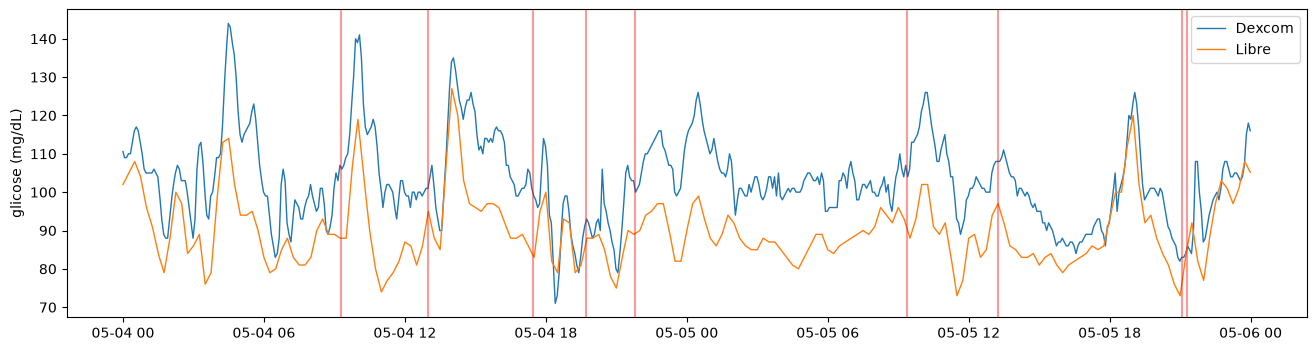

In [27]:
import matplotlib.pyplot as plt

# 1) recorte: 04/05 e 05/05 (dias completos nos dois sensores)
dia = df[(df['Timestamp'] >= '2020-05-04') & (df['Timestamp'] < '2020-05-06')]

# 2) só as linhas em que houve refeição, dentro do recorte
refeicoes = dia[dia['Meal Type'].notna()]

# 3) gráfico
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(dia['Timestamp'], dia['Dexcom GL'], label='Dexcom', lw=1)
ax.plot(dia['Timestamp'], dia['Libre GL'], label='Libre', lw=1)

for t in refeicoes['Timestamp']:
    ax.axvline(t, color='red', alpha=0.4)

ax.set_ylabel('glicose (mg/dL)')
ax.legend()
plt.show()

Cada linha vermelha é uma refeição. A glicose sobe depois delas, sinal de que os horários registrados batem com a resposta do corpo. Para o projeto, é uma boa notícia: se a alimentação mexe na glicose de forma visível, a rede tem o que aprender.

Mas são dois dias de uma pessoa só, e o gráfico mostra associação, não causa. O pico pode ter outras influências, como atividade física.

E nos dias parciais, como fica a curva? Abaixo, o primeiro e o último dia do 001:

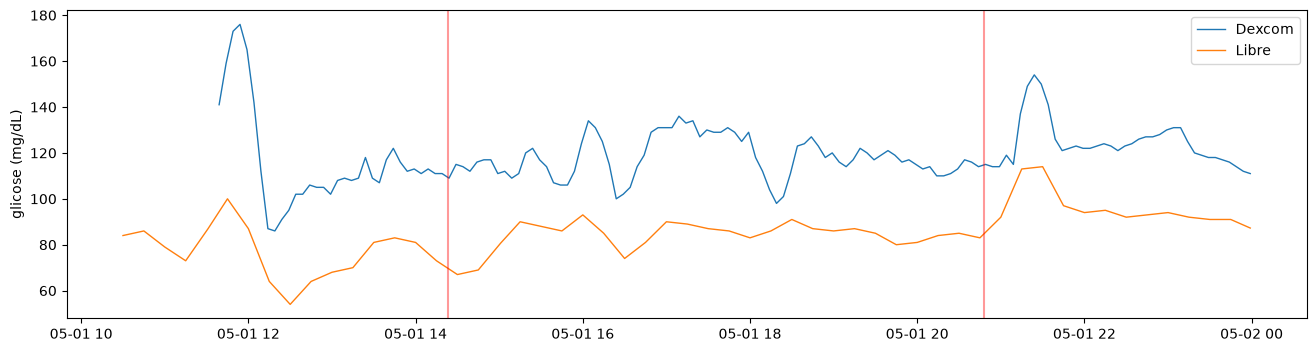

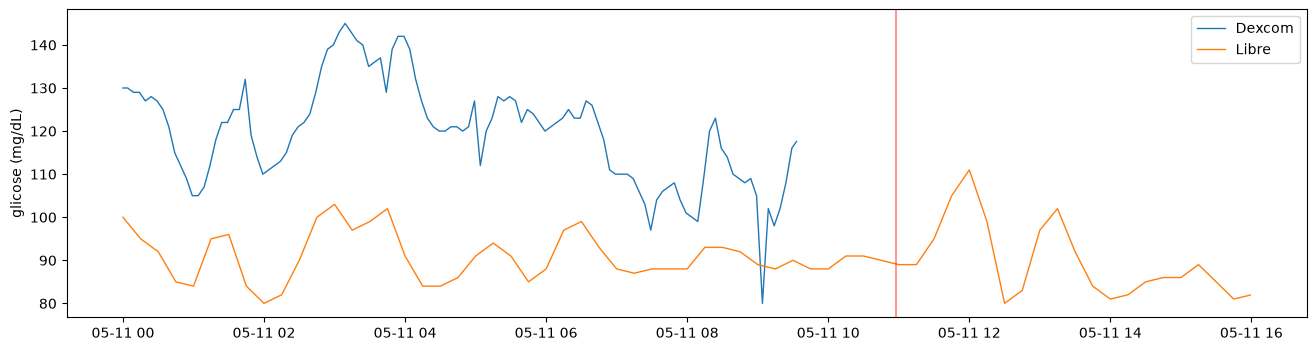

In [29]:
import matplotlib.pyplot as plt

def plot_periodo(df, ini, fim):
    p = df[(df['Timestamp'] >= ini) & (df['Timestamp'] < fim)]
    ref = p[p['Meal Type'].notna()]

    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(p['Timestamp'], p['Dexcom GL'], label='Dexcom', lw=1)
    ax.plot(p['Timestamp'], p['Libre GL'], label='Libre', lw=1)
    for t in ref['Timestamp']:
        ax.axvline(t, color='red', alpha=0.4)
    ax.set_ylabel('glicose (mg/dL)')
    ax.legend()
    plt.show()

plot_periodo(df, '2020-05-01', '2020-05-02')   # primeiro dia (começa 10h30)
plot_periodo(df, '2020-05-11', '2020-05-12')   # último dia (termina 15h59)

No dia 01/05, que começa às 10h30, o Dexcom só começa a registrar por volta das 11h40. Logo no início há uma subida e uma queda bruscas (de ~176 para ~87 mg/dL) sem nenhuma refeição antes, porque o café da manhã aconteceu antes de o registro começar. O jantar aparece normalmente, com o pico em seguida.

No dia 11/05, que termina às 15h59, o Dexcom para por volta das 9h30. A única refeição do dia, perto das 11h, cai nesse buraco: só o Libre mostra a subida, e ele está preenchido.

A forma da curva continua parecida, mas esses dias não podem ser comparados com os inteiros. Falta a madrugada, o café da manhã ou a leitura do próprio sensor que escolhemos. A glicose média e o total de carboidratos sairiam incompletos, e por isso ficamos só com dias inteiros.

Os dias inteiros também mostraram uma coisa que vale guardar: a glicose sobe depois das refeições, mas há picos sem refeição nenhuma antes (como o de ~144 mg/dL às 4h30 de 04/05), e nem toda refeição gera um pico claro. Refeição leva a pico, mas nem todo pico vem de uma refeição registrada. Refeições esquecidas são um limite dos dados e podem confundir o modelo.

### Regra de "dia completo": quanta glicose precisa ter sido medida?

Ter 1440 linhas só diz que o relógio rodou, não que o sensor mediu. Para decidir quais dias usar, calculamos a **cobertura** de cada pessoa-dia: a fração dos 1440 minutos em que o Dexcom tem valor (1,0 é o dia todo).

Nesta primeira versão, entram só as datas com exatamente 1440 linhas, para os dias parciais não atrapalharem. Depois contamos quantos dias sobram em cada corte (100%, 95%, 90% e 80%) e olhamos a distribuição. A ideia é escolher o corte pelos dados, e não no chute: exigir 100% pode jogar fora dias bons por falhas pequenas, e aceitar pouco deixa entrar dias com buracos grandes, que distorcem a média e o pico.

De 416 pessoas-dia, sobram 366 com 100%, 384 com 95% e 385 com 90% ou 80%. O histograma tem dois grupos: quase todos os dias ficam perto de 1,0, e o resto fica entre 0 e 0,4, sem nada entre 0,4 e 0,9. Escolhemos 90%, e nesta versão qualquer corte entre 40% e 90% manteria os mesmos dias.

Um limite: a cobertura diz quanto falta, mas não onde. Os 10% que faltam podem ser uma lacuna única de 2h24 logo depois de uma refeição, escondendo o pico. Isso não foi tratado.

Mais abaixo essa análise é refeita sem o filtro de 1440 linhas, e alguns números mudam.

In [30]:
pids = sorted(int(p.name.split('-')[1]) for p in RAW.glob('CGMacros-*') if p.is_dir())

linhas = []
for pid in pids:
    d = carregar(pid)
    g = d.groupby(d['Timestamp'].dt.date)
    t = pd.DataFrame({'minutos': g.size(), 'dexcom': g['Dexcom GL'].count()})
    t['pid'] = pid
    linhas.append(t.reset_index())

cob = pd.concat(linhas)
cob = cob[cob['minutos'] == 1440]          # só datas inteiras no relógio
cob['cobertura'] = cob['dexcom'] / 1440    # fração de minutos com glicose

1.0 366 de 416
0.95 384 de 416
0.9 385 de 416
0.8 385 de 416


<Axes: >

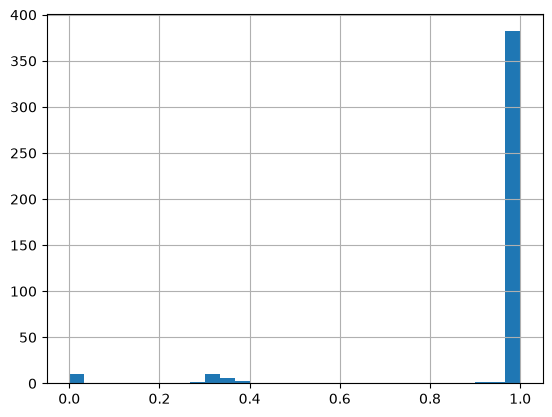

In [31]:
for corte in [1.0, 0.95, 0.90, 0.80]:
    print(corte, (cob['cobertura'] >= corte).sum(), 'de', len(cob))

cob['cobertura'].hist(bins=30)

In [32]:
cob[cob['cobertura'] < 0.5].groupby('pid').size()

pid
2     2
10    1
13    1
14    2
16    1
17    1
20    1
21    1
22    2
23    1
26    2
28    3
29    2
30    1
33    1
36    2
39    2
45    1
47    1
48    2
49    1
dtype: int64

In [33]:
cob = cob.sort_values(['pid', 'Timestamp'])
cob['bom'] = cob['cobertura'] >= 0.90
cob['pos'] = cob.groupby('pid').cumcount()                      # 0 = primeiro dia completo
cob['n'] = cob.groupby('pid')['pos'].transform('max') + 1       # total de dias completos

ruins = cob[~cob['bom']]
ruins[['pid', 'Timestamp', 'cobertura', 'pos', 'n']]

,pid,Timestamp,cobertura,pos,n
10,2,2019-11-25,0.339583,9,11
11,2,2019-11-26,0.000000,10,11
10,10,2020-07-01,0.347917,9,10
10,13,2024-02-04,0.366667,9,10
10,14,2023-05-19,0.338194,9,11
11,14,2023-05-20,0.000000,10,11
10,16,2023-07-24,0.345833,9,10
10,17,2023-10-20,0.330556,9,10
10,20,2024-03-29,0.281944,9,10
10,21,2020-06-18,0.304167,9,10


### Onde estão os dias ruins?

A tabela lista os 31 dias (de 416) em que o Dexcom mediu menos de 90% do dia. `pos` é a posição do dia entre os dias completos do participante (0 é o primeiro), e `n` é o total.

Quase todos (29 de 31) estão no fim do registro: são o último dia ou parte de um bloco que vai até ele, como os três últimos dias do 028. Muitos têm cobertura perto de 30%, ou seja, o Dexcom parou por volta das 8h daquele dia e não voltou mais. A exceção é o 026, com dois dias ruins no meio (o 5º e o 6º de 10).

Uma hipótese é que o Dexcom tenha um tempo de uso limitado, de uns 10 dias, menor que o período de registro. Isso ainda precisa ser conferido na documentação do sensor.

A posição importa porque o projeto precisa de 9 dias seguidos. Um dia ruim no fim só encurta o período; no meio, quebra a sequência.

In [ ]:
# para o projeto, cada participante precisa de 9 dias bons SEGUIDOS (D1..D9)
def maior_sequencia(b):
    grupos = (b != b.shift()).cumsum()     # novo grupo cada vez que alterna entre bom e ruim
    return b.groupby(grupos).sum().max()   # tamanho do maior bloco de dias bons

seq = cob.groupby('pid')['bom'].apply(maior_sequencia)
print('participantes na tabela:', len(seq), 'de', len(pids))
print('com 9 ou mais dias bons seguidos:', (seq >= 9).sum())
seq.sort_values().head(10)

### Quantos participantes têm 9 dias bons seguidos?

O código dá 35 de 45, mas esse número está errado, e o culpado é o filtro `minutos == 1440` usado para montar a tabela:

1. O 007 sumiu (44 em vez de 45). O arquivo dele não tem uma linha por minuto (os intervalos variam de 1 a 7 minutos), então nenhuma data chega a 1440 linhas.
2. Dias quase completos foram descartados. Vários participantes têm datas com 1410 ou 1425 linhas, faltando só 15 ou 30 minutos, e o filtro jogou essas datas fora. Isso quebrou a sequência de participantes que, na prática, estão bons: 003, 015, 019, 033, 043, 046 e 048.
3. O erro é silencioso: quando uma data some do meio, o código junta os dias de antes e de depois como se fossem seguidos.

A correção é medir a cobertura em todas as datas, sem esse filtro. Um dia parcial, como o de 810 minutos, já fica abaixo de 90% por conta própria, então a regra de cobertura resolve os dias parciais também. As datas sem nenhuma linha entram no calendário com cobertura 0, para a sequência respeitar os dias de verdade.

In [ ]:
# versão corrigida: cobertura em TODAS as datas, sem filtrar por 1440 linhas
linhas = []
for pid in pids:
    d = carregar(pid)
    g = d.groupby(d['Timestamp'].dt.normalize())   # data (meia-noite) de cada linha
    t = pd.DataFrame({'minutos': g.size(), 'dexcom': g['Dexcom GL'].count()})
    # completa o calendário: datas sem nenhuma linha entram com 0 leituras
    t = t.reindex(pd.date_range(t.index.min(), t.index.max(), freq='D'), fill_value=0)
    t['pid'] = pid
    linhas.append(t.rename_axis('data').reset_index())

cob2 = pd.concat(linhas)
cob2['cobertura'] = cob2['dexcom'] / 1440
cob2['bom'] = cob2['cobertura'] >= 0.90

seq2 = cob2.groupby('pid')['bom'].apply(maior_sequencia)
print('com 9 ou mais dias bons seguidos:', (seq2 >= 9).sum(), 'de', len(pids))
seq2[seq2 < 9]

### Resultado corrigido e decisão

Com a cobertura medida em todas as datas, 42 dos 45 participantes têm pelo menos 9 dias bons seguidos. Ficam de fora três:

| Participante | Maior sequência | Motivo |
|---|---|---|
| 007 | 0 | o arquivo não tem uma linha por minuto (intervalos de 1 a 7 min), então nenhum dia chega a 90% |
| 018 | 8 | há um intervalo de cerca de 9 datas quase sem registro no meio do período |
| 026 | 4 | o Dexcom falhou no meio do período (dias 5 e 6) |

Mantivemos o corte de 90%, mas a justificativa mudou um pouco em relação à primeira versão. Qualquer corte entre 70% e 95% dá praticamente o mesmo resultado (393 a 395 dias bons e 42 participantes). Exigir 100% deixaria só 22 participantes, e abaixo de 70% começam a entrar dias parciais.

Fica definido, então: um participante é válido se tiver pelo menos 9 dias bons seguidos (D1 a D9), e os excluídos são o 007, o 018 e o 026. O 007 talvez pudesse ser recuperado com outro tratamento, como reamostrar o arquivo para uma linha por minuto, mas não fizemos isso.

## 2. Checagens nos 45 participantes

### As colunas são iguais em todos os arquivos?

Antes de juntar todo mundo numa tabela só, vale conferir se os 45 arquivos têm as mesmas colunas. Se uma coluna faltar em algum, o código quebra ou, pior, a variável fica vazia sem nenhum aviso.

In [ ]:
from collections import Counter

# em quantos dos 45 arquivos cada coluna aparece
contagem = Counter()
for pid in pids:
    cols = pd.read_csv(RAW / f'CGMacros-{pid:03d}' / f'CGMacros-{pid:03d}.csv', nrows=0).columns
    contagem.update(cols)

pd.Series(contagem).sort_values()

In [ ]:
# em quais arquivos faltam as colunas que importam para o projeto
for col in ['Calories (Activity)', 'METs', 'Amount Consumed']:
    faltam = [p for p in pids if col not in carregar(p).columns]
    print(f'{col}: falta em {len(faltam)} arquivos -> {faltam}')

A coluna `METs` falta em 11 arquivos, enquanto `Calories (Activity)` só falta no 007, que já foi excluído. Por isso a atividade vai ser medida por `Calories (Activity)`. Um cuidado: ela soma cerca de 2600 kcal por dia, então inclui o que o corpo gasta em repouso, e não só exercício. Faz mais sentido comparar dias da mesma pessoa do que pessoas diferentes.

`Amount Consumed` falta no 028 e no 029 e, no 001, aparece com um espaço no fim do nome (`'Amount Consumed '`). Para não tropeçar nisso, a função `carregar` passou a tirar os espaços das pontas dos nomes das colunas (`df.columns.str.strip()`).

Algumas colunas aparecem em poucos arquivos (`Intensity`, `Steps`, `Sugar`, `RecordIndex`) e não vamos usá-las. `Unnamed: 0` é só o número da linha, sem informação.

### Libre × Dexcom em todos os participantes

Até aqui, a comparação entre os sensores tinha sido feita só no 001. Agora ela é repetida nos 45, para ver se a escolha do Dexcom vale para todos. Para cada participante, calculamos:
- quantas medições reais por dia cada sensor tem, contando só os dias em que ele tem valor em pelo menos 90% dos minutos;
- a diferença média entre os dois (Libre − Dexcom), nos minutos em que os dois têm valor;
- a correlação entre eles, que mostra se sobem e descem juntos.

In [ ]:
# Libre x Dexcom em todos os participantes
linhas_s = []
for pid in pids:
    d = carregar(pid)
    d['data'] = d['Timestamp'].dt.normalize()
    linha = {'pid': pid}
    for col, nome in [('Libre GL', 'libre'), ('Dexcom GL', 'dexcom')]:
        # medição nova = minuto em que a inclinação da reta muda (mesma ideia do diff no 001)
        variacao = d[col].diff().round(4)
        nova = (variacao != variacao.shift()) & d[col].notna()
        # conta só nos dias em que o sensor tem valor em pelo menos 90% dos minutos
        n_dia = d.groupby('data')[col].count()
        bons = n_dia[n_dia >= 0.9 * 1440].index
        linha[f'{nome}_reais_dia'] = nova[d['data'].isin(bons)].sum() / max(len(bons), 1)
    # nos minutos em que os dois têm valor: diferença média e correlação
    ambos = d.dropna(subset=['Libre GL', 'Dexcom GL'])
    linha['libre_menos_dexcom'] = (ambos['Libre GL'] - ambos['Dexcom GL']).mean()
    linha['correlacao'] = ambos['Libre GL'].corr(ambos['Dexcom GL'])
    linhas_s.append(linha)

sensores = pd.DataFrame(linhas_s)
print('Libre abaixo do Dexcom em', (sensores['libre_menos_dexcom'] < 0).sum(), 'de', len(sensores), 'participantes')
sensores.drop(columns='pid').describe().round(1)

In [ ]:
# participantes em que os dois sensores menos concordam
sensores.sort_values('correlacao').head(6).round(2)

O padrão do 001 se repete. Nos dias bons, o Libre tem uma mediana de ~88 medições reais por dia e o Dexcom, ~242, cerca de 2,7 vezes mais. (Os números ficam abaixo de 96 e 288 porque o método conta duas medições seguidas com a mesma inclinação como se fossem uma.) A vantagem do Dexcom vale para praticamente todo mundo.

O que surpreende é o quanto os dois discordam. O Libre marca menos que o Dexcom em 44 dos 45 participantes, em média 32 mg/dL a menos. A correlação entre eles tem mediana de 0,8, mas em alguns participantes (013, 007, 008, 032 e 006) os dois quase não andam juntos, com correlação entre 0,1 e 0,4.

Isso tem duas consequências. A primeira é que os sensores não podem ser misturados: trocar de um para o outro mudaria a glicose em ~30 mg/dL sem que nada tivesse acontecido. A segunda é que escolhemos o Dexcom pela resolução, e não por ele ser mais preciso. Sem uma medida de referência, não dá para saber qual dos dois está mais perto da glicose real, e valores absolutos como "% do tempo acima de 140 mg/dL" dependem do sensor.

Uma referência possível seriam as 3 medições por picada no dedo do `bio.csv` (`Contour Fingerstick GLU`), mas o arquivo só traz o horário, sem a data, e essa comparação ficou de fora.

### Grupo clínico

O `bio.csv` não diz quem é saudável, pré-diabético ou DM2, então o grupo foi criado a partir da HbA1c (hemoglobina glicada, que reflete a glicose média dos últimos ~3 meses), com os cortes da American Diabetes Association (ADA):

| HbA1c | Grupo |
|---|---|
| < 5,7% | saudável |
| 5,7% a 6,4% | pré-diabetes |
| ≥ 6,5% | DM2 |

In [ ]:
bio = pd.read_csv(RAW / 'bio.csv')

# critério da ADA para HbA1c: < 5,7 normal; 5,7 a 6,4 pré-diabetes; >= 6,5 diabetes
bio['grupo'] = pd.cut(bio['A1c PDL (Lab)'], bins=[0, 5.7, 6.5, 100], right=False,
                      labels=['saudável', 'pré-diabetes', 'DM2'])

print(bio['grupo'].value_counts())

In [ ]:
# quem está perto dos cortes (uma mudança pequena no exame mudaria o grupo)
perto = bio[bio['A1c PDL (Lab)'].between(5.5, 6.6)]
perto[['subject', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'grupo']].sort_values('A1c PDL (Lab)')

O resultado é 15 saudáveis, 16 com pré-diabetes e 14 com DM2, exatamente os números descritos no dataset, o que indica que é o mesmo critério dos autores.

A classificação, porém, depende de um único exame, e vários participantes estão bem perto dos cortes (5,6% ou 6,5%, por exemplo). Uma pequena variação no exame mudaria o grupo deles. A glicemia de jejum também nem sempre concorda com a HbA1c: o 045 tem HbA1c de 6,1%, faixa de pré-diabetes, mas glicemia de jejum de 148 mg/dL, que pelo critério de jejum já seria diabetes.

### Tabela com um dia por linha (versão da EDA)

Para comparar grupos e fazer os scatters, os dados minuto a minuto viram uma linha por pessoa-dia. Entram só os dias bons (Dexcom ≥ 90%) dos 42 participantes válidos, e para cada dia calculamos:
- da glicose (Dexcom): média, desvio padrão, pico e % do tempo acima de 140 mg/dL;
- da alimentação: total de carboidratos e número de refeições registradas;
- da atividade: soma de `Calories (Activity)`.

Ainda não é a tabela final do pré-processamento, que vai ter também proteína, gordura, fibra, horário da última refeição e os dados do `bio.csv`, mas já dá para olhar as relações.

In [ ]:
excluidos = seq2[seq2 < 9].index.tolist()
validos = [p for p in pids if p not in excluidos]
print('excluídos:', excluidos)

def resumo_dia(pid):
    d = carregar(pid)
    d['data'] = d['Timestamp'].dt.normalize()
    g = d.groupby('data')
    t = pd.DataFrame({
        'dexcom_n':    g['Dexcom GL'].count(),
        'glic_media':  g['Dexcom GL'].mean(),
        'glic_dp':     g['Dexcom GL'].std(),
        'glic_pico':   g['Dexcom GL'].max(),
        'pct_140':     g['Dexcom GL'].apply(lambda s: (s.dropna() > 140).mean() * 100),
        'carbs':       g['Carbs'].sum(),
        'n_refeicoes': g['Meal Type'].count(),
        'kcal_ativ':   g['Calories (Activity)'].sum(),
    })
    t = t[t['dexcom_n'] >= 0.9 * 1440]      # só dias bons
    t['pid'] = pid
    return t.reset_index()

dias = pd.concat([resumo_dia(p) for p in validos], ignore_index=True)
dias = dias.merge(bio[['subject', 'grupo']], left_on='pid', right_on='subject').drop(columns='subject')
print(len(dias), 'pessoas-dia de', dias['pid'].nunique(), 'participantes')
print(dias.groupby('grupo', observed=True)['pid'].nunique())
dias.head()

In [ ]:
dias.describe().round(1)

Ficaram 378 pessoas-dia de 42 participantes, 14 em cada grupo. As exclusões tiraram um saudável e dois pré-diabéticos, e os grupos acabaram equilibrados.

O `describe()` mostra alguns valores estranhos que vão precisar de tratamento no pré-processamento:
- 5 dias com mais de 500 g de carboidrato (a mediana é 188 g), nos participantes 004, 021 e 036, talvez erro de registro ou refeição duplicada;
- 1 dia com 0 caloria gasta (participante 033), ou seja, o Fitbit não foi usado;
- 9 dias com pico de 400 mg/dL, que é o limite do sensor; nesses dias, o pico real pode ter sido maior.

### Refeições

Os carboidratos de cada dia saem das refeições registradas, então um registro falho estraga justamente uma das variáveis que a rede mais vai usar.

In [ ]:
# rótulos de refeição e quanto da refeição foi consumido, nos 45 arquivos
rotulos, consumo, sem_consumo = [], [], []
for pid in pids:
    d = carregar(pid)
    r = d[d['Meal Type'].notna()]
    rotulos.append(r['Meal Type'])
    if 'Amount Consumed' in d.columns:
        consumo.append(r['Amount Consumed'])
    else:
        sem_consumo.append(pid)

rotulos = pd.concat(rotulos)
consumo = pd.concat(consumo)
print(rotulos.value_counts(), '\n')
print('refeições com consumo diferente de 100%:', (consumo != 100).sum(), 'de', len(consumo))
print('refeições com consumo acima de 100%:', (consumo > 100).sum(), '| máximo:', consumo.max())
print('arquivos sem a coluna Amount Consumed:', sem_consumo)

In [ ]:
# refeições registradas por dia, em média, por participante (os 8 que menos registram)
dias.groupby('pid')['n_refeicoes'].mean().sort_values().head(8).round(2)

O mesmo tipo de refeição aparece escrito de vários jeitos (`dinner` e `Dinner`; `snack`, `Snacks`, `Snack` e `snack 1`). Se o tipo for usado no modelo, vai precisar ser padronizado.

`Amount Consumed`, que diz quanto da refeição foi comido, é diferente de 100% em 522 das 1642 refeições, e 131 delas passam de 100% (chegando a 900%), o que não faz sentido para uma porcentagem. Como a coluna não parece confiável e ainda falta no 028 e no 029, por enquanto os carboidratos são usados como foram registrados.

Em média, cada participante registra umas 4 refeições por dia. Os que menos registram (042 e 032) ficam perto de 2, o que sugere refeições esquecidas. Não excluímos ninguém por isso, mas fica o limite: um dia com "poucos carboidratos" pode ser só um dia com refeições que não foram anotadas.

### Glicose por grupo clínico

Se os grupos fazem sentido, a glicose deveria aumentar de saudável para pré-diabetes e de pré-diabetes para DM2. É mais um teste de sanidade dos dados.

In [ ]:
cols = ['glic_media', 'glic_dp', 'glic_pico', 'pct_140', 'carbs', 'kcal_ativ', 'n_refeicoes']
display(dias.groupby('grupo', observed=True)[cols].mean().round(1))

ordem = ['saudável', 'pré-diabetes', 'DM2']
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([dias.loc[dias['grupo'] == g, 'glic_media'] for g in ordem])
ax.set_xticklabels(ordem)
ax.axhline(140, color='gray', ls='--', lw=1)   # referência: 140 mg/dL
ax.set_ylabel('glicose média do dia (mg/dL)')
plt.show()

E aumenta:

| | saudável | pré-diabetes | DM2 |
|---|---|---|---|
| glicose média do dia (mg/dL) | 121 | 137 | 167 |
| pico do dia (mg/dL) | 182 | 214 | 279 |
| % do tempo acima de 140 | 17% | 34% | 67% |
| carboidratos (g/dia) | 220 | 212 | 170 |

Os grupos se sobrepõem, porém: há dias de pré-diabéticos com glicose mais alta que dias de quem tem DM2. E a última linha traz um detalhe que vai pesar logo adiante: quem tem DM2 come menos carboidrato, provavelmente por orientação médica.

### Carboidratos e atividade × glicose

A pergunta aqui é simples: em dias com mais carboidrato, ou com menos atividade, a glicose média é maior? Se não houver relação nenhuma, a rede não vai ter o que aprender.

In [ ]:
cores = {'saudável': 'tab:green', 'pré-diabetes': 'tab:orange', 'DM2': 'tab:red'}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g, s in dias.groupby('grupo', observed=True):
    axes[0].scatter(s['carbs'], s['glic_media'], s=12, alpha=0.6, color=cores[g], label=g)
    axes[1].scatter(s['kcal_ativ'], s['glic_media'], s=12, alpha=0.6, color=cores[g], label=g)
axes[0].set_xlabel('carboidratos do dia (g)')
axes[1].set_xlabel('calorias gastas no dia (Fitbit)')
for ax in axes:
    ax.set_ylabel('glicose média do dia (mg/dL)')
    ax.legend()
plt.show()

print('correlação carbs x glicose:', round(dias['carbs'].corr(dias['glic_media']), 3))
print('correlação atividade x glicose:', round(dias['kcal_ativ'].corr(dias['glic_media']), 3))

O resultado surpreende. Misturando todo mundo, a correlação entre carboidratos e glicose é negativa (−0,19), como se dias com mais carboidrato tivessem glicose menor. A atividade quase não aparece relacionada (−0,06).

Fisiologicamente isso não faz sentido, e o próprio gráfico explica o porquê: os pontos vermelhos (DM2) ficam no alto e à esquerda, porque essas pessoas têm glicose alta e, ao mesmo tempo, comem menos carboidrato. A correlação está comparando pessoas diferentes, e não o efeito de comer mais.

Para enxergar o efeito de verdade, é preciso comparar cada dia com a média da própria pessoa.

In [ ]:
# quanto cada dia se afasta da média DAQUELA pessoa (tira a diferença entre pessoas)
def desvio_pessoa(col):
    return dias[col] - dias.groupby('pid')[col].transform('mean')

dentro = pd.DataFrame({c: desvio_pessoa(c) for c in ['carbs', 'kcal_ativ', 'glic_media']})
dentro['grupo'] = dias['grupo']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g, s in dentro.groupby('grupo', observed=True):
    axes[0].scatter(s['carbs'], s['glic_media'], s=12, alpha=0.6, color=cores[g], label=g)
    axes[1].scatter(s['kcal_ativ'], s['glic_media'], s=12, alpha=0.6, color=cores[g], label=g)
axes[0].set_xlabel('carboidratos: diferença da média da pessoa (g)')
axes[1].set_xlabel('calorias gastas: diferença da média da pessoa')
for ax in axes:
    ax.set_ylabel('glicose: diferença da média da pessoa')
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.legend()
plt.show()

print('dentro da pessoa, carbs x glicose:', round(dentro['carbs'].corr(dentro['glic_media']), 3))
print('dentro da pessoa, atividade x glicose:', round(dentro['kcal_ativ'].corr(dentro['glic_media']), 3))

In [ ]:
# a mesma correlação calculada separadamente para cada participante
corr_pp = dias.groupby('pid')[['carbs', 'kcal_ativ', 'glic_media']].apply(
    lambda s: pd.Series({'carbs': s['carbs'].corr(s['glic_media']),
                         'kcal_ativ': s['kcal_ativ'].corr(s['glic_media'])}))
print('participantes com correlação positiva carbs x glicose:', round((corr_pp['carbs'] > 0).mean(), 2))
print('participantes com correlação negativa atividade x glicose:', round((corr_pp['kcal_ativ'] < 0).mean(), 2))

# e por grupo clínico
for g, s in dentro.groupby('grupo', observed=True):
    print(f"{g}: carbs {s['carbs'].corr(s['glic_media']):.2f} | atividade {s['kcal_ativ'].corr(s['glic_media']):.2f}")

Comparando cada pessoa com ela mesma, o sinal do carboidrato se inverte. A correlação vira +0,13 e é positiva em 79% dos participantes: no dia em que alguém come mais carboidrato do que costuma, a glicose dele fica mais alta. A atividade também aparece: −0,23, negativa em 62% dos participantes, ou seja, dias mais ativos têm glicose mais baixa. O efeito é mais forte no grupo DM2 (−0,35).

É o chamado **paradoxo de Simpson**: uma relação aparece num sentido nos dados misturados e no sentido contrário dentro de cada grupo.

Isso mexe com o projeto em três pontos. A rede precisa saber quem é a pessoa, recebendo a glicose dos dias anteriores e os dados do `bio.csv`; sem isso, ela pode aprender que mais carboidrato baixa a glicose, e o algoritmo genético acabaria recomendando comer mais carboidrato. Os efeitos também são fracos (correlações entre 0,1 e 0,35), então é de esperar que a recomendação mude pouco a glicose. E correlação não é causa: um dia mais ativo pode ser diferente em outras coisas, como sono, estresse ou refeições não registradas.

In [ ]:
total = dias['glic_media'].std()
dentro_sd = desvio_pessoa('glic_media').std()
print('desvio padrão da glicose média diária, total:', round(total, 1))
print('desvio padrão dentro da mesma pessoa:', round(dentro_sd, 1))
print('fração da variação explicada por "quem é a pessoa":', round(1 - dentro_sd**2 / total**2, 2))

dias = dias.sort_values(['pid', 'data'])
ontem = dias.groupby('pid')['glic_media'].shift()
print('erro médio de prever "hoje = ontem" (MAE):', round((dias['glic_media'] - ontem).abs().mean(), 2), 'mg/dL')

A glicose média diária varia cerca de 30 mg/dL entre todas as pessoas-dia, mas só uns 9 mg/dL dentro de uma mesma pessoa. Cerca de 90% da variação vem de quem é a pessoa, e só o resto muda de um dia para o outro.

Por isso, prever que "a glicose de hoje vai ser igual à de ontem" (a persistência) já erra só 8,1 mg/dL em média. É esse número que a rede precisa bater para ser útil; comparar com a média geral faria qualquer modelo parecer ótimo sem ter aprendido nada. E a margem que o comportamento tem para mexer na glicose é pequena, de poucos mg/dL.

## 3. Resumo das decisões da EDA

| Decisão | Escolha | Por quê |
|---|---|---|
| Sensor | Dexcom | tem ~2,7 vezes mais medições reais que o Libre nos 45 participantes e capta melhor os picos; a escolha é por resolução, não por precisão |
| Dia | data do calendário, de 00:00 a 23:59 | permite juntar glicose, refeições e atividade do mesmo dia |
| Dia bom | Dexcom com valor em ≥ 90% dos 1440 minutos | qualquer corte entre 70% e 95% dá praticamente o mesmo resultado; com 100% sobrariam só 22 participantes; dias parciais ficam de fora sozinhos |
| Participante válido | ≥ 9 dias bons seguidos | o projeto usa D1..D6 para observar e D7..D9 para recomendar |
| Exclusões | 007, 018 e 026 | arquivo irregular, ~9 datas sem registro e Dexcom falhando no meio do período |
| Grupo clínico | HbA1c pelos cortes da ADA | reproduz os 15/16/14 descritos no dataset |
| Atividade | `Calories (Activity)` | `METs` falta em 11 arquivos |

**Dataset para as próximas etapas:** 42 participantes (14 por grupo) e 378 dias bons.

**Pendências para o pré-processamento:**
- padronizar os rótulos de refeição;
- decidir o que fazer com `Amount Consumed` (valores acima de 100% e ausente no 028 e no 029);
- tratar os dias com carboidrato muito alto, o dia sem Fitbit e os picos cortados em 400 mg/dL;
- escolher quais 9 dias seguidos de cada participante usar.

**Principais achados para a apresentação:**
1. Os dois sensores são interpolados, e a "completude" do Libre é aparente. Eles também discordam: o Libre marca ~32 mg/dL a menos que o Dexcom em 44 de 45 participantes, então não podem ser misturados.
2. Cerca de 90% da variação da glicose diária vem de quem é a pessoa, e prever "hoje = ontem" já erra só ~8 mg/dL.
3. Paradoxo de Simpson: misturando pessoas, mais carboidrato parece baixar a glicose; dentro da mesma pessoa, aumenta. O modelo precisa conhecer a pessoa.
4. Mais atividade física está associada a glicose mais baixa, principalmente no grupo DM2.